HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

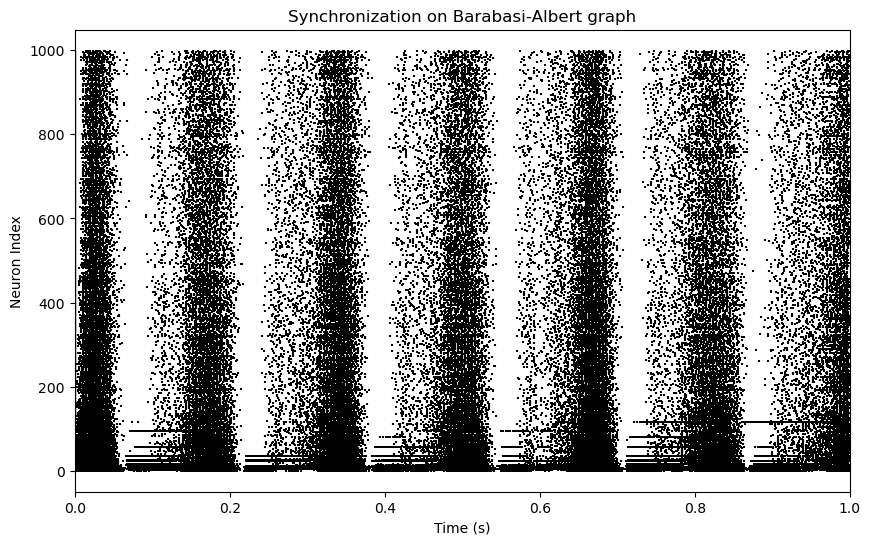

In [28]:
# https://arxiv.org/abs/2304.08281

import numpy as np
import nengo
import networkx as nx
import matplotlib.pyplot as plt

# network
N = 1000        # number of neurons
m = 3           # each node connects to m existing nodes
g_coupling = 0.5  # strength of synaptic connections

graph = nx.barabasi_albert_graph(n=N, m=m, seed=42)
adjacency_matrix = nx.to_numpy_array(graph)



def create_model(weights):
    model = nengo.Network(label="scale free synchronization")

    with model:
        neurons = nengo.Ensemble(
            n_neurons=N,
            dimensions=1,
            neuron_type=nengo.Izhikevich(), 
            encoders=np.ones((N, 1)),
            intercepts=np.zeros(N),          # Identical thresholds
            max_rates=np.ones(N) * 5         # Identical baseline speeds (50 Hz)
        )
        
        # bckground drive 
        bg_input = nengo.Node(0.5)
        nengo.Connection(bg_input, neurons.neurons, transform=np.ones((N, 1)))
        
        nengo.Connection(
            neurons.neurons, 
            neurons.neurons, 
            transform=weights, #adjacency_matrix * 0.15, # Replaced g_coupling variable with inline 0.15
            synapse=0.01  
        )
        
        spike_probe = nengo.Probe(neurons.neurons, 'output')

    return model, spike_probe

model, spike_probe = create_model(adjacency_matrix * 0.15)

def simulate_and_plot(T):
    with nengo.Simulator(model) as sim:
        sim.run(T)  

    # plotting
    plt.figure(figsize=(10, 6))
    # indices where spikes occurred
    time_indices, neuron_indices = np.where(sim.data[spike_probe] > 0)
    # convert time indices to seconds 
    spike_times = time_indices * sim.dt

    plt.scatter(spike_times, neuron_indices, s=2, color='black', marker='|')
    plt.title(f"Synchronization on Barabasi-Albert graph")
    plt.xlabel("Time (s)")
    plt.ylabel("Neuron Index")
    plt.xlim(0, T)
    plt.show()

T = 1  # in seconds

simulate_and_plot(T)

Running Forward Sweep...


HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

... (21 outputs left out)

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

HtmlProgressBar cannot be displayed. Please use the TerminalProgressBar. It can be enabled with `nengo.rc['progress']['progress_bar'] = 'nengo.utils.progress.TerminalProgressBar'`.

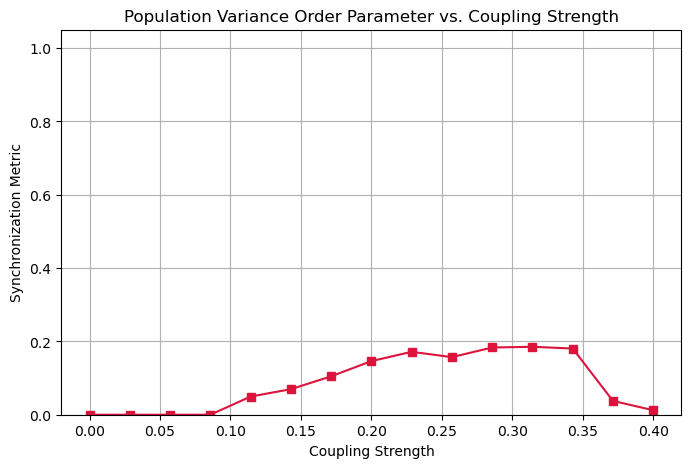

In [ ]:
def order_parameter(spike_data, dt=0.001):
    """ time-domain synchronization order parameter R for izhikevich neurons."""
    # Skip the first 200ms to allow the network to settle into a steady state
    warmup = int(0.2 / dt)
    steady_data = spike_data[warmup:]

    pop_activity = np.mean(steady_data, axis=1)
    var_pop = np.var(pop_activity)
    
    var_indiv = np.mean(np.var(steady_data, axis=0))
    
    if var_indiv == 0: return 0
    return var_pop / var_indiv

def order_parameter2(sim_data): #, voltage_probe):
    """Computes the Chi (population variance) synchronization metric."""
    # Shape: (timesteps, N)
    v_matrix = sim_data #sim_data[voltage_probe]  
    
    # Drop transient dynamics (first 70% of simulation) to focus on steady state
    steady_state_start = int(v_matrix.shape[0] * 0.7)
    v_stable = v_matrix[steady_state_start:, :]
    
    # 1. Time-series of the population average voltage
    pop_mean_v = np.mean(v_stable, axis=1)
    
    # 2. Variance of the population average over time
    var_pop_mean = np.var(pop_mean_v)
    
    # 3. Average of the individual neuron variances over time
    var_individuals = np.var(v_stable, axis=0)
    mean_var_individuals = np.mean(var_individuals)
    
    # Prevent division by zero if neurons aren't updating/moving
    if mean_var_individuals == 0:
        return 0.0
        
    # Chi metric calculation
    chi = np.sqrt(var_pop_mean / mean_var_individuals)
    return chi


def run_nengo_network(weights, T):
    model, probe = create_model(weights)
    with nengo.Simulator(model) as sim:
        sim.run(T)  
    return order_parameter(sim.data[probe])
    
    #chi_values.append(chi)
    #print(f"Coupling: {g:.2f} -> Synchronization (Chi): {chi:.3f}")


g_values = np.linspace(0.0, 0.4, 15)  # Sweep range for coupling scale
R_forward = []

print("Running Forward Sweep...")
for g in g_values:
    R = run_nengo_network(adjacency_matrix * g, 1.0)
    R_forward.append(R)


plt.figure(figsize=(8, 5))
plt.plot(g_values, R_forward, marker='s', linestyle='-', color='crimson')
plt.title("Population Variance Order Parameter vs. Coupling Strength")
plt.xlabel("Coupling Strength")
plt.ylabel("Synchronization Metric")
plt.grid(True)
plt.ylim(0, 1.05)
plt.show()




    
    




